# Practical No. 04: Image Generation Using DCGAN on CIFAR-10

**Name:** Tanishka Vishnu Tapkir

**Batch:** A3

**PRN:** 202401110071

**Dataset:** CIFAR-10 subset containing 5,000 images (500 images per class)

## Aim

To build and train a Deep Convolutional Generative Adversarial Network (DCGAN) to generate synthetic 32 × 32 RGB images.

## Important Information

This notebook uses the uploaded `cifar10_5000_subset.zip` dataset instead of downloading the complete CIFAR-10 dataset through TensorFlow. The dataset contains ten class folders, with 500 images per class.

The DCGAN is trained unconditionally. The Generator learns to produce synthetic images resembling the overall training-data distribution; it does not generate a specific requested class.



## 1. Check hardware and import libraries

In [4]:
import os, zipfile, glob, random
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf

print("TensorFlow:", tf.__version__)
print("GPU available:", bool(tf.config.list_physical_devices("GPU")))
SEED = 42
tf.random.set_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)

TensorFlow: 2.21.0
GPU available: True


## 2. Upload and extract the dataset ZIP
Run this cell and select `cifar10_5000_subset.zip` from your computer.

In [2]:
import zipfile
import os
import glob
from google.colab import files

uploaded = files.upload()

zip_files = [
    name for name in uploaded
    if name.lower().endswith(".zip")
]

if not zip_files:
    raise ValueError("Please upload the cifar10_5000_subset.zip file.")

zip_path = zip_files[0]
extract_dir = "/content/cifar10_subset"

with zipfile.ZipFile(zip_path, "r") as zf:
    zf.extractall(extract_dir)

image_paths = sorted(
    glob.glob(os.path.join(extract_dir, "**", "*.jpg"), recursive=True)
)
image_paths += sorted(
    glob.glob(os.path.join(extract_dir, "**", "*.jpeg"), recursive=True)
)
image_paths += sorted(
    glob.glob(os.path.join(extract_dir, "**", "*.png"), recursive=True)
)

print("Images found:", len(image_paths))

if len(image_paths) == 0:
    raise ValueError(
        "No image files were found in the ZIP. Check the ZIP contents."
    )

Saving cifar10_5000_subset.zip to cifar10_5000_subset (1).zip
Images found: 5000


## 3. Load and preprocess images
Images are resized to 32 × 32 RGB and normalized to `[-1, 1]`, matching the Generator's `tanh` output.

In [5]:
IMG_SIZE = 32
BATCH_SIZE = 128

images = []
for path in image_paths:
    try:
        img = Image.open(path).convert("RGB").resize((IMG_SIZE, IMG_SIZE))
        images.append(np.asarray(img, dtype=np.float32))
    except Exception as e:
        print("Skipping unreadable image:", path, e)

images = np.array(images, dtype=np.float32)
images = (images / 127.5) - 1.0

print("Dataset shape:", images.shape)
print("Pixel range:", float(images.min()), "to", float(images.max()))

dataset = tf.data.Dataset.from_tensor_slices(images)
dataset = dataset.shuffle(min(len(images), 5000), seed=SEED, reshuffle_each_iteration=True)
dataset = dataset.batch(BATCH_SIZE, drop_remainder=True).prefetch(tf.data.AUTOTUNE)

Dataset shape: (5000, 32, 32, 3)
Pixel range: -1.0 to 1.0


## 4. Visualize real dataset images

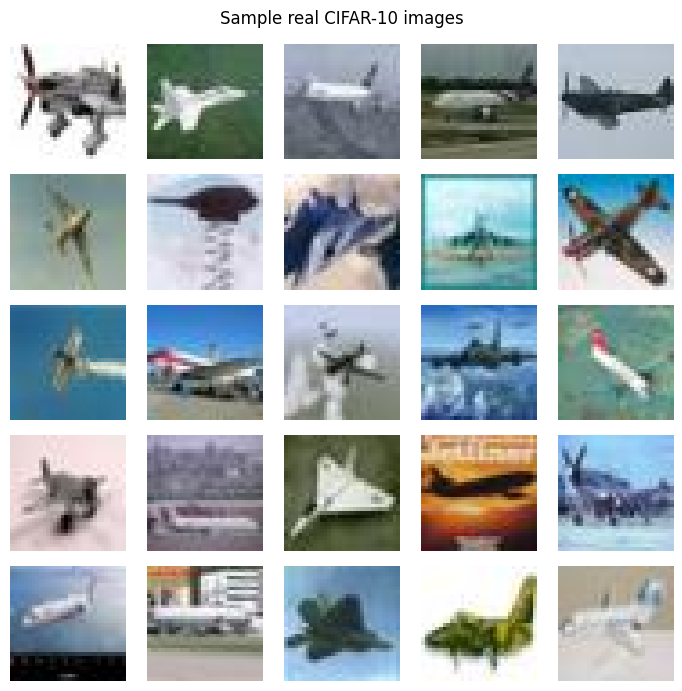

In [6]:
def show_image_grid(imgs, title, n=5, normalized=False):
    fig, axes = plt.subplots(n, n, figsize=(7, 7))
    for i, ax in enumerate(axes.flat):
        if i < len(imgs):
            image = imgs[i]
            if normalized:
                image = (image + 1.0) / 2.0
            ax.imshow(np.clip(image, 0, 1))
        ax.axis("off")
    plt.suptitle(title)
    plt.tight_layout()
    plt.show()

show_image_grid(images[:25], "Sample real CIFAR-10 images", normalized=True)

## 5. Build the Generator
The Generator maps random noise (latent vectors) into 32 × 32 RGB images.

In [7]:
LATENT_DIM = 100

def build_generator():
    model = tf.keras.Sequential(name="Generator")
    model.add(tf.keras.layers.Input(shape=(LATENT_DIM,)))
    model.add(tf.keras.layers.Dense(4 * 4 * 256, use_bias=False))
    model.add(tf.keras.layers.BatchNormalization())
    model.add(tf.keras.layers.LeakyReLU())
    model.add(tf.keras.layers.Reshape((4, 4, 256)))

    model.add(tf.keras.layers.Conv2DTranspose(128, 4, strides=2, padding="same", use_bias=False))
    model.add(tf.keras.layers.BatchNormalization())
    model.add(tf.keras.layers.LeakyReLU())

    model.add(tf.keras.layers.Conv2DTranspose(64, 4, strides=2, padding="same", use_bias=False))
    model.add(tf.keras.layers.BatchNormalization())
    model.add(tf.keras.layers.LeakyReLU())

    model.add(tf.keras.layers.Conv2DTranspose(3, 4, strides=2, padding="same", activation="tanh"))
    return model

generator = build_generator()
generator.summary()

Model: "Generator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 4096)           │       409,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 4096)           │        16,384 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 8, 8, 128)      │       524,288 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 16, 16, 64)     │       131,072 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_2              │ (None, 32, 32, 3)      │         3,075 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,085,187 (4.14 MB)

 Trainable params: 1,076,611 (4.11 MB)

 Non-trainable params: 8,576 (33.50 KB)

## 6. Build the Discriminator
The Discriminator classifies each image as real or generated.

In [8]:
def build_discriminator():
    model = tf.keras.Sequential(name="Discriminator")
    model.add(tf.keras.layers.Input(shape=(32, 32, 3)))
    model.add(tf.keras.layers.Conv2D(64, 4, strides=2, padding="same"))
    model.add(tf.keras.layers.LeakyReLU(negative_slope=0.2))
    model.add(tf.keras.layers.Dropout(0.3))

    model.add(tf.keras.layers.Conv2D(128, 4, strides=2, padding="same"))
    model.add(tf.keras.layers.LeakyReLU(negative_slope=0.2))
    model.add(tf.keras.layers.Dropout(0.3))

    model.add(tf.keras.layers.Conv2D(256, 4, strides=2, padding="same"))
    model.add(tf.keras.layers.LeakyReLU(negative_slope=0.2))
    model.add(tf.keras.layers.Dropout(0.3))

    model.add(tf.keras.layers.Flatten())
    model.add(tf.keras.layers.Dense(1))  # logits, no sigmoid
    return model

discriminator = build_discriminator()
discriminator.summary()

Model: "Discriminator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 16, 16, 64)     │         3,136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 8, 8, 128)      │       131,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_4 (LeakyReLU)       │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 4, 4, 256)      │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_5 (LeakyReLU)       │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │         4,097 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 662,977 (2.53 MB)

 Trainable params: 662,977 (2.53 MB)

 Non-trainable params: 0 (0.00 B)

## 7. Configure losses and optimizers
Binary cross-entropy is used to train the Discriminator and Generator adversarially.

In [15]:
cross_entropy = tf.keras.losses.BinaryCrossentropy(from_logits=True)

def discriminator_loss(real_output, fake_output):
    real_loss = cross_entropy(tf.ones_like(real_output), real_output)
    fake_loss = cross_entropy(tf.zeros_like(fake_output), fake_output)
    return real_loss + fake_loss

def generator_loss(fake_output):
    return cross_entropy(tf.ones_like(fake_output), fake_output)

generator_optimizer = tf.keras.optimizers.Adam(
    learning_rate=0.0001,
    beta_1=0.5
)

discriminator_optimizer = tf.keras.optimizers.Adam(
    learning_rate=0.0001,
    beta_1=0.5
)

fixed_noise = tf.random.normal([25, LATENT_DIM])

## 8. Train the DCGAN
Start with 5 epochs for a practical demonstration. GAN training can take several minutes depending on the assigned Colab hardware. Images may remain blurry at this small training budget.

In [16]:
@tf.function
def train_step(real_images):
    noise = tf.random.normal(
        [tf.shape(real_images)[0], LATENT_DIM]
    )

    with tf.GradientTape() as gen_tape, tf.GradientTape() as disc_tape:
        generated_images = generator(noise, training=True)

        real_output = discriminator(real_images, training=True)
        fake_output = discriminator(generated_images, training=True)

        gen_loss = generator_loss(fake_output)
        disc_loss = discriminator_loss(real_output, fake_output)

    gradients_of_generator = gen_tape.gradient(
        gen_loss, generator.trainable_variables
    )
    gradients_of_discriminator = disc_tape.gradient(
        disc_loss, discriminator.trainable_variables
    )

    generator_optimizer.apply_gradients(
        zip(gradients_of_generator, generator.trainable_variables)
    )
    discriminator_optimizer.apply_gradients(
        zip(gradients_of_discriminator, discriminator.trainable_variables)
    )

    return gen_loss, disc_loss


# Train for 100 epochs
EPOCHS = 100
gen_losses, disc_losses = [], []

for epoch in range(EPOCHS):
    epoch_gen, epoch_disc, batches = 0.0, 0.0, 0

    for real_batch in dataset:
        g_loss, d_loss = train_step(real_batch)
        epoch_gen += float(g_loss)
        epoch_disc += float(d_loss)
        batches += 1

    avg_g = epoch_gen / max(batches, 1)
    avg_d = epoch_disc / max(batches, 1)

    gen_losses.append(avg_g)
    disc_losses.append(avg_d)

    print(
        f"Epoch {epoch+1}/{EPOCHS} | "
        f"Generator loss: {avg_g:.4f} | "
        f"Discriminator loss: {avg_d:.4f}"
    )

Epoch 1/100 | Generator loss: 2.3120 | Discriminator loss: 0.4457
Epoch 2/100 | Generator loss: 2.2967 | Discriminator loss: 0.5143
Epoch 3/100 | Generator loss: 2.2022 | Discriminator loss: 0.5571
Epoch 4/100 | Generator loss: 2.2141 | Discriminator loss: 0.5082
Epoch 5/100 | Generator loss: 2.1124 | Discriminator loss: 0.5704
Epoch 6/100 | Generator loss: 2.2637 | Discriminator loss: 0.5419
Epoch 7/100 | Generator loss: 2.2005 | Discriminator loss: 0.5580
Epoch 8/100 | Generator loss: 2.2059 | Discriminator loss: 0.5371
Epoch 9/100 | Generator loss: 2.3824 | Discriminator loss: 0.4713
Epoch 10/100 | Generator loss: 2.3693 | Discriminator loss: 0.5056
Epoch 11/100 | Generator loss: 2.4124 | Discriminator loss: 0.5254
Epoch 12/100 | Generator loss: 2.3196 | Discriminator loss: 0.5011
Epoch 13/100 | Generator loss: 2.2656 | Discriminator loss: 0.5247
Epoch 14/100 | Generator loss: 2.7954 | Discriminator loss: 0.4322
Epoch 15/100 | Generator loss: 2.4478 | Discriminator loss: 0.5994
Epoc

## 9. Generate synthetic images

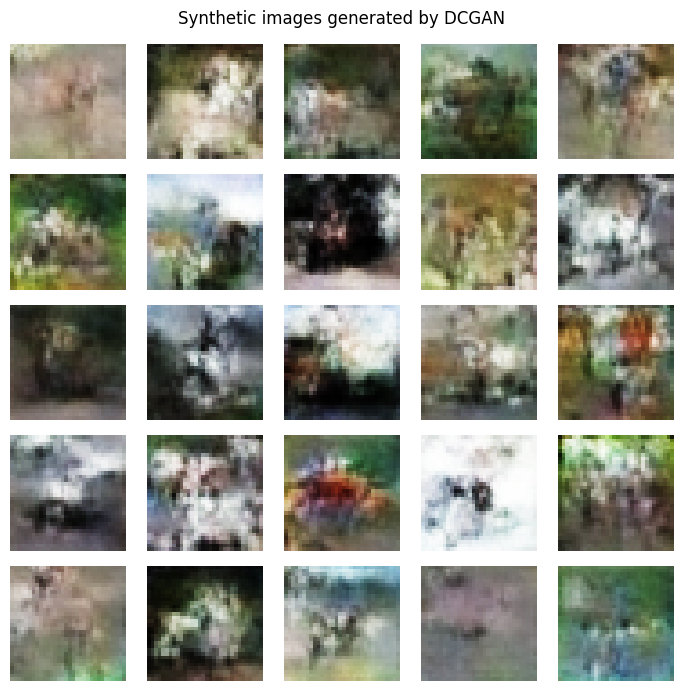

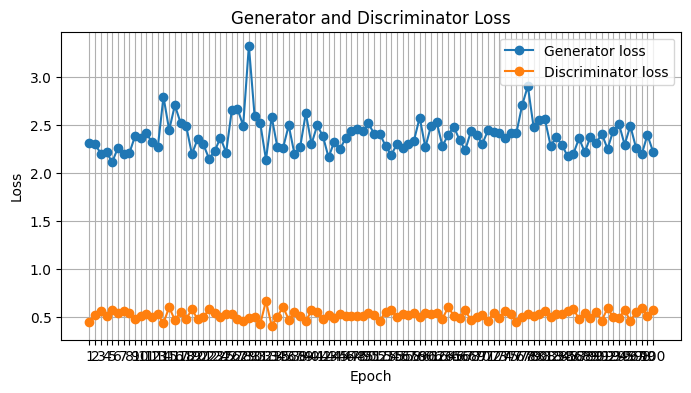

In [17]:
generated = generator(fixed_noise, training=False).numpy()
show_image_grid(generated, "Synthetic images generated by DCGAN", normalized=True)

plt.figure(figsize=(8, 4))
plt.plot(range(1, EPOCHS + 1), gen_losses, marker="o", label="Generator loss")
plt.plot(range(1, EPOCHS + 1), disc_losses, marker="o", label="Discriminator loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Generator and Discriminator Loss")
plt.xticks(range(1, EPOCHS + 1))
plt.legend()
plt.grid(True)
plt.show()

## 10. Save the model and generated images

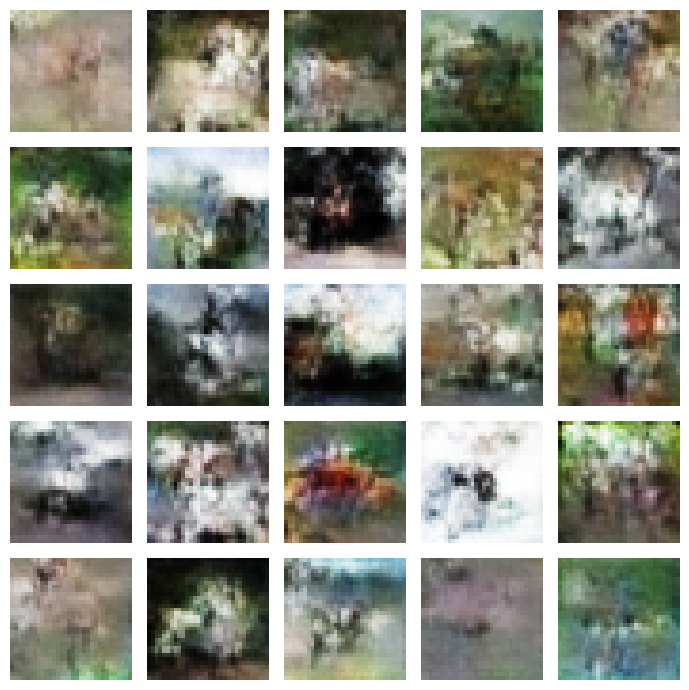

Saved Generator: /content/cifar10_dcgan_generator.keras
Saved Discriminator: /content/cifar10_dcgan_discriminator.keras
Saved image grid: /content/dcgan_generated_images.png


In [18]:
generator.save("/content/cifar10_dcgan_generator.keras")
discriminator.save("/content/cifar10_dcgan_discriminator.keras")

generated_uint8 = np.clip((generated + 1.0) * 127.5, 0, 255).astype(np.uint8)
fig, axes = plt.subplots(5, 5, figsize=(7, 7))
for i, ax in enumerate(axes.flat):
    ax.imshow(generated_uint8[i])
    ax.axis("off")
plt.tight_layout()
plt.savefig("/content/dcgan_generated_images.png", dpi=150)
plt.show()

print("Saved Generator: /content/cifar10_dcgan_generator.keras")
print("Saved Discriminator: /content/cifar10_dcgan_discriminator.keras")
print("Saved image grid: /content/dcgan_generated_images.png")

## Result
A DCGAN was implemented using a 5,000-image CIFAR-10 subset. The Generator learned to produce 32 × 32 RGB synthetic images from random latent vectors, while the Discriminator learned to distinguish real images from generated images. Generator and Discriminator losses were recorded and plotted across epochs.

## Conclusion
The practical demonstrates adversarial image generation using a Deep Convolutional GAN. The quality of generated images depends on training duration, dataset size, and model stability. Since this run uses a limited subset and only five epochs, the images may be blurry and should be interpreted as a demonstration rather than high-quality generation.